In [2]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset

In [3]:
# Menggunakan sep='\t' karena filenya dipisahkan oleh tab
df = pd.read_csv('cpa.csv', sep='\t')

#Step2: lakukan Eksplorasi awal

In [4]:
print("=== Info Dataset ===")
print(df.info())
print("\n=== Jumlah Missing Value ===")
# Tampilkan yang nill
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\n=== Tampilkan 5 Data Teratas ===")
print(df.head())

# Menghapus kolom identifi & yg tdk bervariasi
df_clean = df.drop(columns=['ID','Z_CostContact','Z_Revenue'])

# Konversi tanggal customer ke numerik (jml hari berlangganan)
df_clean['Dt_Customer'] = pd.to_datetime(df_clean['Dt_Customer'], format='%d-%m-%Y')
max_date = df_clean['Dt_Customer'].max()
df_clean['Days_Customer'] = (max_date - df_clean['Dt_Customer']).dt.days

# Hapus kolom tanggal yg asli krn sdh diganti dgn Days_Customer
df_clean = df_clean.drop(columns = ['Dt_Customer'])

=== Info Dataset ===
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 no

# Step 3: Identifikasi kolom numerik & kategori

In [5]:
cat_cols = ['Education', 'Marital_Status']
num_cols = [col for col in df_clean.columns if col not in cat_cols]

# Step 4: Imputasi missing value

In [6]:
# Menggunakan median utk fitur numerik
imputer = SimpleImputer(strategy='median')
df_clean[num_cols] = imputer.fit_transform(df_clean[num_cols])


# Step 5: Encoding fitur kategori

In [7]:
# Encoding  menggunakan pd.get_dummies
df_encoded = pd.get_dummies(df_clean[cat_cols], drop_first=False, dtype=int)

# Gabung data numerik & hasil encoding
X_combined =  pd.concat([df_clean[num_cols], df_encoded], axis=1)


# Step 6: Scaling data

In [8]:
scaler = StandardScaler()
X_scaled =  scaler.fit_transform(X_combined)

# Mengembalikan ke bentuk DataFrame agar kolomnya teteap bernama
X_scaled_df = pd.DataFrame(X_scaled, columns=X_combined.columns)


# Step 7: Tentukan jumlah cluster optimal (Elbow + Silhouette)

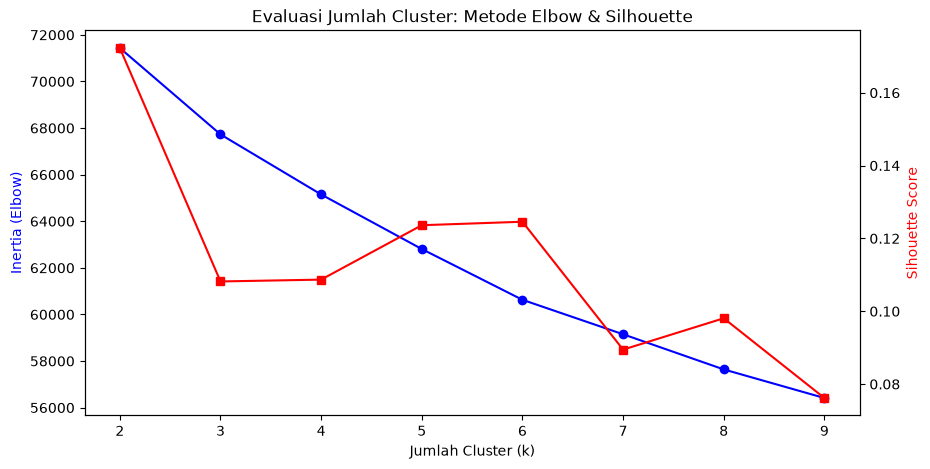

In [9]:
inertias = []
sil_scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled_df)
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled_df, kmeans.labels_))

# Visualisasi gabungan Elbow & Silhoutte
fig, ax1 = plt.subplots(figsize = (10,5))
ax1.plot(K_range, inertias, marker='o', color='blue', label='Inertia')
ax1.set_xlabel('Jumlah Cluster (k)')
ax1.set_ylabel('Inertia (Elbow)', color='blue')

ax2 = ax1.twinx()
ax2.plot(K_range, sil_scores, marker='s', color='red', label='Silhoutte Score')
ax2.set_ylabel('Sihouette Score', color='red')

plt.title('Evaluasi Jumlah Cluster: Metode Elbow & Silhouette')
plt.show()

# Step 8: Pilih k optimal dan klasterisasi

In [10]:
# Asumsi dari evaluasi visual k=4
k_optimal = 4
kmeans_final = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)

# Prediksi label cluster dan simpan ke dataframe yg blm discale
df_clean['Cluster'] = kmeans_final.fit_predict(X_scaled_df)

# Step 9: Visualisasi klaster dengan PCA 2D

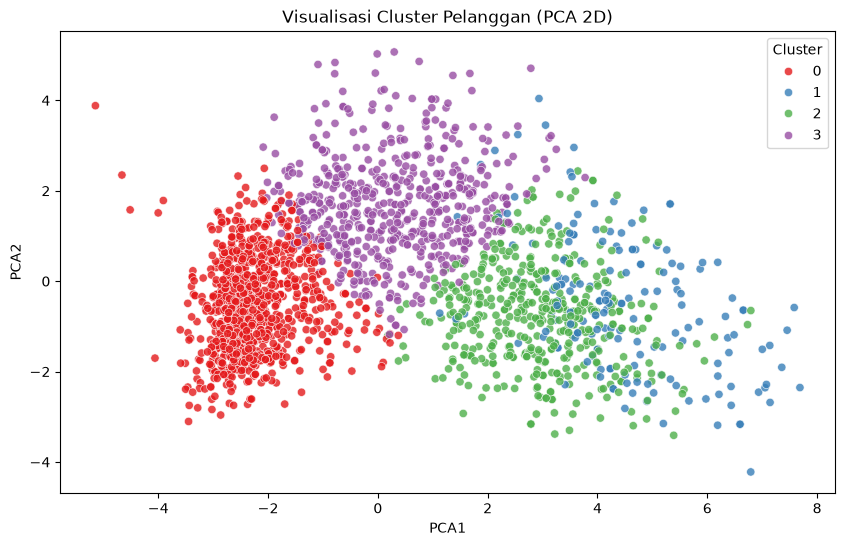

In [11]:
# Reduksi dimensi menjadi 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_df)

df_clean['PCA1'] = X_pca[:, 0]
df_clean['PCA2'] = X_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', palette='Set1', data=df_clean, alpha=0.8)
plt.title('Visualisasi Cluster Pelanggan (PCA 2D)')
plt.show()

# Step 10: Profiling cluster (rata-rata fitur per cluster)

In [12]:
# MEnghitung rata-rata
cluster_profiling = df_clean.groupby('Cluster')[num_cols].mean()

print("\n=== Profiling Cluster (Rata-rata Fitur) ===")

print(cluster_profiling.T.round(2))


=== Profiling Cluster (Rata-rata Fitur) ===
Cluster                     0         1         2         3
Year_Birth            1971.95   1969.36   1967.96   1964.01
Income               34713.60  81569.49  73853.65  56805.05
Kidhome                  0.80      0.05      0.05      0.25
Teenhome                 0.43      0.13      0.24      0.95
Recency                 49.57     49.83     49.37     47.94
MntWines                38.15    874.70    488.42    446.86
MntFruits                5.01     56.43     70.86     19.44
MntMeatProducts         22.80    469.13    426.71    124.60
MntFishProducts          7.30     77.05    104.93     25.54
MntSweetProducts         5.13     65.48     71.60     18.94
MntGoldProds            15.37     77.34     77.22     57.28
NumDealsPurchases        2.00      1.05      1.52      3.84
NumWebPurchases          2.06      5.44      5.25      6.20
NumCatalogPurchases      0.53      6.05      5.73      2.93
NumStorePurchases        3.16      8.26      8.36      

# Simpulkan Analisa dari hasil

In [13]:
"""
Berikut adalah kesimpulan dan analisis dari hasil pemrosesan data:

1. Karakteristik Pelanggan
Dataset berhasil dikelompokkan menjadi 4 profil pelanggan yang sangat berbeda berdasarkan tingkat pendapatan, komposisi keluarga, dan perilaku belanja:
a. Pelanggan Ekonomis (Klaster 0)
Merupakan kelompok terbesar. Memiliki pendapatan rata-rata terendah (~$34.700) dan mayoritas memiliki anak kecil di rumah. Total pengeluaran paling rendah di semua kategori produk (terutama Wine dan Daging). Frekuensi belanja di toko fisik maupun web sangat rendah. Sangat berhati-hati dalam mengeluarkan uang dan kemungkinan besar sangat sensitif terhadap harga atau diskon.

b. Pelanggan Premium (Klaster 1)
Kelompok eksklusif dengan pendapatan tertinggi (~$81.500) dan rata-rata tidak memiliki tanggungan anak kecil atau remaja di rumah. Merupakan penyumbang omzet terbesar perusahaan. Pembelian produk premium sangat tinggi, khususnya pada Wine (rata-rata 874) dan Daging (rata-rata 469). Sangat sering berbelanja langsung di toko fisik (lebih dari 8 kali).

c. Pelanggan Mapan Aktif (Klaster 2)
Pendapatan tinggi (~$73.800), demografi keluarga mirip dengan segmen premium (sedikit/tidak ada tanggungan anak). Pengeluaran belanja cukup besar namun lebih bervariasi (tidak hanya terpusat di Wine seperti Segmen 2). Mereka sangat aktif berbelanja di berbagai saluran, baik melalui web maupun toko fisik secara berimbang.

d. Pelanggan Menengah & Keluarga dengan Remaja (Klaster 3)
Kelompok dengan pendapatan menengah (~$56.800). Ciri utamanya adalah hampir seluruhnya memiliki anak remaja (rata-rata mendekati 1). Tingkat konsumsi moderat (menengah). Frekuensi belanja via web cukup tinggi (rata-rata 6 kali).

2. Rekomendasi
Dari analisis di atas, perusahaan dapat menerapkan strategi pemasaran yang lebih terarah dibandingkan memberikan promosi acak ke semua orang:
- Strategi untuk Segmen Premium & Mapan (Klaster 1 & 2): Jangan terlalu sering memberikan diskon karena kelompok ini tidak sensitif harga. Kirimkan katalog produk premium edisi terbatas (terutama Wine dan Daging berkualitas). Pastikan pelayanan di toko fisik (in-store experience) sangat baik, karena mereka paling sering berkunjung ke toko.
- Strategi untuk Segmen Keluarga / Remaja (Klaster 3): Fokuskan kampanye pemasaran melalui platform digital (Web/Email) karena mereka memiliki interaksi web yang tinggi. Tawarkan produk-produk kebutuhan harian atau bundling dalam ukuran keluarga (family pack).
- Strategi untuk Segmen Ekonomis (Klaster 0): Kelompok ini butuh dorongan untuk bertransaksi. Kirimkan promosi harga coret (diskon besar), flash sale, atau kupon promosi yang berfokus pada produk kebutuhan esensial dan perlengkapan anak.
"""

'\nBerikut adalah kesimpulan dan analisis dari hasil pemrosesan data:\n\n1. Karakteristik Pelanggan\nDataset berhasil dikelompokkan menjadi 4 profil pelanggan yang sangat berbeda berdasarkan tingkat pendapatan, komposisi keluarga, dan perilaku belanja:\na. Pelanggan Ekonomis (Klaster 0)\nMerupakan kelompok terbesar. Memiliki pendapatan rata-rata terendah (~$34.700) dan mayoritas memiliki anak kecil di rumah. Total pengeluaran paling rendah di semua kategori produk (terutama Wine dan Daging). Frekuensi belanja di toko fisik maupun web sangat rendah. Sangat berhati-hati dalam mengeluarkan uang dan kemungkinan besar sangat sensitif terhadap harga atau diskon.\n\nb. Pelanggan Premium (Klaster 1)\nKelompok eksklusif dengan pendapatan tertinggi (~$81.500) dan rata-rata tidak memiliki tanggungan anak kecil atau remaja di rumah. Merupakan penyumbang omzet terbesar perusahaan. Pembelian produk premium sangat tinggi, khususnya pada Wine (rata-rata 874) dan Daging (rata-rata 469). Sangat sering b